In [102]:
import numpy as np
import pandas as pd
from sklearn import set_config
set_config(transform_output="pandas")
import matplotlib.pyplot as plt

In [104]:
df=pd.read_csv('pargi_voters_1000_natural_complete.csv',usecols=['age','distance_from_assigned_polling_booth_km','voted_status'])
df.shape


(1000, 3)

In [105]:
df.head()

,age,distance_from_assigned_polling_booth_km,voted_status
0,51,1.51,1
1,27,1.11,1
2,65,1.82,1
3,54,2.60,1
4,67,4.60,0


In [106]:
from sklearn.preprocessing import LabelEncoder
lb=LabelEncoder()
df['voted_status']=lb.fit_transform(df['voted_status'])
df.head()

,age,distance_from_assigned_polling_booth_km,voted_status
0,51,1.51,1
1,27,1.11,1
2,65,1.82,1
3,54,2.60,1
4,67,4.60,0


In [107]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

df1 = pd.DataFrame(
    scaler.fit_transform(df[['age', 'distance_from_assigned_polling_booth_km']]),
    columns=['age', 'distance_from_assigned_polling_booth_km']
)

df1['voted_status'] = df['voted_status'].values

df1.head()

,age,distance_from_assigned_polling_booth_km,voted_status
0,0.315125,-0.796296,1
1,-1.101169,-1.228948,1
2,1.141297,-0.460991,1
3,0.492162,0.382681,1
4,1.259322,2.545942,0


In [108]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
X = df1.drop('voted_status', axis=1)
y = df1['voted_status']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

lr = LogisticRegression()
lr.fit(X_train, y_train)

y_pred = lr.predict(X_test)

accuracy_score(y_test, y_pred)

0.89

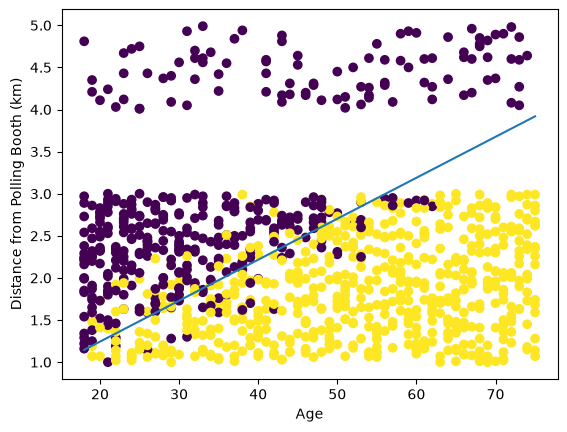

In [109]:
x = np.linspace(df['age'].min(), df['age'].max(), 100)

x_scaled = scaler.transform(
    pd.DataFrame({
        'age': x,
        'distance_from_assigned_polling_booth_km': np.zeros(100)
    })
).iloc[:, 0]

y_scaled = -(lr.intercept_[0] + lr.coef_[0][0] * x_scaled) / lr.coef_[0][1]

y_line = y_scaled * scaler.scale_[1] + scaler.mean_[1]

plt.scatter(df['age'], df['distance_from_assigned_polling_booth_km'], c=y)
plt.plot(x, y_line)
plt.xlabel('Age')
plt.ylabel('Distance from Polling Booth (km)')
plt.show()

In [110]:
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

In [111]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.ensemble import StackingClassifier
from xgboost import XGBClassifier


In [112]:
import optuna

In [113]:
def objective(trial):

    classifier_name = trial.suggest_categorical(
        'classifier',
        [
            'SVM',
            'RandomForest',
            'GradientBoosting',
            'StackingClassifier',
            'VotingClassifier',
            'AdaBoostClassifier',
            'BaggingClassifier',
            'KNeighborsClassifier',
            'XGBClassifier',
            'DecisionTreeClassifier',
            'GaussianNB'
        ]
    )

    # =========================================================
    # 1. SVM
    # =========================================================
    if classifier_name == 'SVM':

        C = trial.suggest_float(
            'svm_C', 0.001, 1000, log=True
        )

        kernel = trial.suggest_categorical(
            'svm_kernel',
            ['linear', 'rbf', 'poly', 'sigmoid']
        )

        gamma = trial.suggest_categorical(
            'svm_gamma',
            ['scale', 'auto']
        )

        degree = trial.suggest_int(
            'svm_degree', 2, 5
        )

        coef0 = trial.suggest_float(
            'svm_coef0', 0.0, 2.0
        )

        class_weight = trial.suggest_categorical(
            'svm_class_weight',
            [None, 'balanced']
        )

        model = SVC(
            C=C,
            kernel=kernel,
            gamma=gamma,
            degree=degree,
            coef0=coef0,
            class_weight=class_weight,
            random_state=42
        )


    # =========================================================
    # 2. RANDOM FOREST
    # =========================================================
    elif classifier_name == 'RandomForest':

        n_estimators = trial.suggest_int(
            'rf_n_estimators', 100, 1000
        )

        max_depth = trial.suggest_int(
            'rf_max_depth', 2, 50
        )

        min_samples_split = trial.suggest_int(
            'rf_min_samples_split', 2, 20
        )

        min_samples_leaf = trial.suggest_int(
            'rf_min_samples_leaf', 1, 20
        )

        max_features = trial.suggest_categorical(
            'rf_max_features',
            ['sqrt', 'log2', None]
        )

        bootstrap = trial.suggest_categorical(
            'rf_bootstrap',
            [True, False]
        )

        criterion = trial.suggest_categorical(
            'rf_criterion',
            ['gini', 'entropy', 'log_loss']
        )

        class_weight = trial.suggest_categorical(
            'rf_class_weight',
            [None, 'balanced', 'balanced_subsample']
        )

        max_leaf_nodes = trial.suggest_categorical(
            'rf_max_leaf_nodes',
            [None, 10, 20, 30, 50, 100]
        )

        min_impurity_decrease = trial.suggest_float(
            'rf_min_impurity_decrease',
            0.0, 0.05
        )

        model = RandomForestClassifier(
            n_estimators=n_estimators,
            max_depth=max_depth,
            min_samples_split=min_samples_split,
            min_samples_leaf=min_samples_leaf,
            max_features=max_features,
            bootstrap=bootstrap,
            criterion=criterion,
            class_weight=class_weight,
            max_leaf_nodes=max_leaf_nodes,
            min_impurity_decrease=min_impurity_decrease,
            random_state=42,
            n_jobs=-1
        )


    # =========================================================
    # 3. GRADIENT BOOSTING
    # =========================================================
    elif classifier_name == 'GradientBoosting':

        n_estimators = trial.suggest_int(
            'gb_n_estimators', 50, 1000
        )

        learning_rate = trial.suggest_float(
            'gb_learning_rate', 0.001, 0.3, log=True
        )

        max_depth = trial.suggest_int(
            'gb_max_depth', 1, 20
        )

        min_samples_split = trial.suggest_int(
            'gb_min_samples_split', 2, 30
        )

        min_samples_leaf = trial.suggest_int(
            'gb_min_samples_leaf', 1, 20
        )

        subsample = trial.suggest_float(
            'gb_subsample', 0.5, 1.0
        )

        max_features = trial.suggest_categorical(
            'gb_max_features',
            [None, 'sqrt', 'log2']
        )

        criterion = trial.suggest_categorical(
            'gb_criterion',
            ['friedman_mse', 'squared_error']
        )

        min_impurity_decrease = trial.suggest_float(
            'gb_min_impurity_decrease',
            0.0, 0.05
        )

        model = GradientBoostingClassifier(
            n_estimators=n_estimators,
            learning_rate=learning_rate,
            max_depth=max_depth,
            min_samples_split=min_samples_split,
            min_samples_leaf=min_samples_leaf,
            subsample=subsample,
            max_features=max_features,
            criterion=criterion,
            min_impurity_decrease=min_impurity_decrease,
            random_state=42
        )


    # =========================================================
    # 4. ADA BOOST
    # =========================================================
    elif classifier_name == 'AdaBoostClassifier':

        n_estimators = trial.suggest_int(
            'ada_n_estimators', 50, 1000
        )

        learning_rate = trial.suggest_float(
            'ada_learning_rate', 0.001, 2.0, log=True
        )

        model = AdaBoostClassifier(
            n_estimators=n_estimators,
            learning_rate=learning_rate,
            random_state=42
        )


    # =========================================================
    # 5. BAGGING
    # =========================================================
    elif classifier_name == 'BaggingClassifier':

        n_estimators = trial.suggest_int(
            'bag_n_estimators', 10, 500
        )

        max_samples = trial.suggest_float(
            'bag_max_samples', 0.3, 1.0
        )

        max_features = trial.suggest_float(
            'bag_max_features', 0.3, 1.0
        )

        bootstrap = trial.suggest_categorical(
            'bag_bootstrap',
            [True, False]
        )

        bootstrap_features = trial.suggest_categorical(
            'bag_bootstrap_features',
            [True, False]
        )

        model = BaggingClassifier(
            n_estimators=n_estimators,
            max_samples=max_samples,
            max_features=max_features,
            bootstrap=bootstrap,
            bootstrap_features=bootstrap_features,
            random_state=42,
            n_jobs=-1
        )


    # =========================================================
    # 6. K NEAREST NEIGHBORS
    # =========================================================
    elif classifier_name == 'KNeighborsClassifier':

        n_neighbors = trial.suggest_int(
            'knn_n_neighbors', 1, 50
        )

        weights = trial.suggest_categorical(
            'knn_weights',
            ['uniform', 'distance']
        )

        algorithm = trial.suggest_categorical(
            'knn_algorithm',
            ['auto', 'ball_tree', 'kd_tree', 'brute']
        )

        leaf_size = trial.suggest_int(
            'knn_leaf_size', 10, 100
        )

        p = trial.suggest_int(
            'knn_p', 1, 5
        )

        model = KNeighborsClassifier(
            n_neighbors=n_neighbors,
            weights=weights,
            algorithm=algorithm,
            leaf_size=leaf_size,
            p=p
        )


    # =========================================================
    # 7. XGBOOST
    # =========================================================
    elif classifier_name == 'XGBClassifier':

        n_estimators = trial.suggest_int(
            'xgb_n_estimators', 100, 1500
        )

        max_depth = trial.suggest_int(
            'xgb_max_depth', 1, 20
        )

        learning_rate = trial.suggest_float(
            'xgb_learning_rate', 0.001, 0.3, log=True
        )

        min_child_weight = trial.suggest_float(
            'xgb_min_child_weight', 0.1, 20, log=True
        )

        subsample = trial.suggest_float(
            'xgb_subsample', 0.5, 1.0
        )

        colsample_bytree = trial.suggest_float(
            'xgb_colsample_bytree', 0.5, 1.0
        )

        gamma = trial.suggest_float(
            'xgb_gamma', 0.0, 10.0
        )

        reg_alpha = trial.suggest_float(
            'xgb_reg_alpha', 1e-8, 10, log=True
        )

        reg_lambda = trial.suggest_float(
            'xgb_reg_lambda', 1e-8, 10, log=True
        )

        max_delta_step = trial.suggest_int(
            'xgb_max_delta_step', 0, 10
        )

        booster = trial.suggest_categorical(
            'xgb_booster',
            ['gbtree', 'dart']
        )

        model = XGBClassifier(
            n_estimators=n_estimators,
            max_depth=max_depth,
            learning_rate=learning_rate,
            min_child_weight=min_child_weight,
            subsample=subsample,
            colsample_bytree=colsample_bytree,
            gamma=gamma,
            reg_alpha=reg_alpha,
            reg_lambda=reg_lambda,
            max_delta_step=max_delta_step,
            booster=booster,
            random_state=42,
            n_jobs=-1,
            eval_metric='logloss'
        )


    # =========================================================
    # 8. DECISION TREE
    # =========================================================
    elif classifier_name == 'DecisionTreeClassifier':

        criterion = trial.suggest_categorical(
            'dt_criterion',
            ['gini', 'entropy', 'log_loss']
        )

        splitter = trial.suggest_categorical(
            'dt_splitter',
            ['best', 'random']
        )

        max_depth = trial.suggest_int(
            'dt_max_depth', 1, 50
        )

        min_samples_split = trial.suggest_int(
            'dt_min_samples_split', 2, 30
        )

        min_samples_leaf = trial.suggest_int(
            'dt_min_samples_leaf', 1, 20
        )

        max_features = trial.suggest_categorical(
            'dt_max_features',
            [None, 'sqrt', 'log2']
        )

        max_leaf_nodes = trial.suggest_categorical(
            'dt_max_leaf_nodes',
            [None, 5, 10, 20, 30, 50, 100]
        )

        min_impurity_decrease = trial.suggest_float(
            'dt_min_impurity_decrease',
            0.0, 0.05
        )

        class_weight = trial.suggest_categorical(
            'dt_class_weight',
            [None, 'balanced']
        )

        ccp_alpha = trial.suggest_float(
            'dt_ccp_alpha',
            0.0, 0.05
        )

        model = DecisionTreeClassifier(
            criterion=criterion,
            splitter=splitter,
            max_depth=max_depth,
            min_samples_split=min_samples_split,
            min_samples_leaf=min_samples_leaf,
            max_features=max_features,
            max_leaf_nodes=max_leaf_nodes,
            min_impurity_decrease=min_impurity_decrease,
            class_weight=class_weight,
            ccp_alpha=ccp_alpha,
            random_state=42
        )


    # =========================================================
    # 9. GAUSSIAN NB
    # =========================================================
    elif classifier_name == 'GaussianNB':

        var_smoothing = trial.suggest_float(
            'gnb_var_smoothing',
            1e-12, 1e-6, log=True
        )

        model = GaussianNB(
            var_smoothing=var_smoothing
        )


    # =========================================================
    # 10. VOTING CLASSIFIER
    # =========================================================
    elif classifier_name == 'VotingClassifier':

        voting = trial.suggest_categorical(
            'voting_type',
            ['hard', 'soft']
        )

        # Tune the important base models
        rf_n_estimators = trial.suggest_int(
            'vote_rf_n_estimators', 100, 500
        )

        rf_max_depth = trial.suggest_int(
            'vote_rf_max_depth', 2, 30
        )

        svm_C = trial.suggest_float(
            'vote_svm_C', 0.01, 100, log=True
        )

        knn_neighbors = trial.suggest_int(
            'vote_knn_neighbors', 2, 30
        )

        rf = RandomForestClassifier(
            n_estimators=rf_n_estimators,
            max_depth=rf_max_depth,
            random_state=42,
            n_jobs=-1
        )

        svm = SVC(
            C=svm_C,
            probability=True,
            random_state=42
        )

        knn = KNeighborsClassifier(
            n_neighbors=knn_neighbors
        )

        model = VotingClassifier(
            estimators=[
                ('rf', rf),
                ('svm', svm),
                ('knn', knn)
            ],
            voting=voting
        )


    # =========================================================
    # 11. STACKING CLASSIFIER
    # =========================================================
    elif classifier_name == 'StackingClassifier':

        rf_n_estimators = trial.suggest_int(
            'stack_rf_n_estimators', 100, 500
        )

        rf_max_depth = trial.suggest_int(
            'stack_rf_max_depth', 2, 30
        )

        svm_C = trial.suggest_float(
            'stack_svm_C', 0.01, 100, log=True
        )

        knn_neighbors = trial.suggest_int(
            'stack_knn_neighbors', 2, 30
        )

        final_C = trial.suggest_float(
            'stack_final_C', 0.01, 100, log=True
        )

        rf = RandomForestClassifier(
            n_estimators=rf_n_estimators,
            max_depth=rf_max_depth,
            random_state=42,
            n_jobs=-1
        )

        svm = SVC(
            C=svm_C,
            probability=True,
            random_state=42
        )

        knn = KNeighborsClassifier(
            n_neighbors=knn_neighbors
        )

        final_estimator = LogisticRegression(
            C=final_C,
            max_iter=2000
        )

        model = StackingClassifier(
            estimators=[
                ('rf', rf),
                ('svm', svm),
                ('knn', knn)
            ],
            final_estimator=final_estimator,
            cv=5,
            n_jobs=-1
        )


    # =========================================================
    # CROSS VALIDATION
    # =========================================================

    score = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring='accuracy',
        n_jobs=-1
    ).mean()

    return score

In [63]:
from sklearn.model_selection import cross_val_score

In [64]:
study=optuna.create_study(direction='maximize')
study.optimize(objective,n_trials=500)

[I 2026-09-05 11:30:03,067] A new study created in memory with name: no-name-cccdd639-0bad-4863-a111-fb26f67c3837
[I 2026-09-05 11:30:10,208] Trial 0 finished with value: 0.9157142857142857 and parameters: {'classifier': 'VotingClassifier', 'voting_type': 'soft', 'vote_rf_n_estimators': 169, 'vote_rf_max_depth': 10, 'vote_svm_C': 0.2947998148915349, 'vote_knn_neighbors': 6}. Best is trial 0 with value: 0.9157142857142857.
[I 2026-09-05 11:30:25,490] Trial 1 finished with value: 0.9128571428571428 and parameters: {'classifier': 'StackingClassifier', 'stack_rf_n_estimators': 482, 'stack_rf_max_depth': 15, 'stack_svm_C': 14.82497904829671, 'stack_knn_neighbors': 21, 'stack_final_C': 0.14494300542805877}. Best is trial 0 with value: 0.9157142857142857.
[I 2026-09-05 11:30:33,199] Trial 2 finished with value: 0.9128571428571428 and parameters: {'classifier': 'StackingClassifier', 'stack_rf_n_estimators': 194, 'stack_rf_max_depth': 7, 'stack_svm_C': 24.068011626327024, 'stack_knn_neighbors':

[I 2026-09-05 11:31:39,667] Trial 23 finished with value: 0.9214285714285715 and parameters: {'classifier': 'StackingClassifier', 'stack_rf_n_estimators': 340, 'stack_rf_max_depth': 22, 'stack_svm_C': 0.357348815291852, 'stack_knn_neighbors': 12, 'stack_final_C': 1.5261178250743057}. Best is trial 23 with value: 0.9214285714285715.
[I 2026-09-05 11:31:39,753] Trial 24 finished with value: 0.9185714285714285 and parameters: {'classifier': 'SVM', 'svm_C': 501.81645304576506, 'svm_kernel': 'linear', 'svm_gamma': 'scale', 'svm_degree': 5, 'svm_coef0': 0.07617312288237266, 'svm_class_weight': 'balanced'}. Best is trial 23 with value: 0.9214285714285715.
[I 2026-09-05 11:31:41,430] Trial 25 finished with value: 0.9157142857142857 and parameters: {'classifier': 'VotingClassifier', 'voting_type': 'hard', 'vote_rf_n_estimators': 459, 'vote_rf_max_depth': 30, 'vote_svm_C': 55.984584096260704, 'vote_knn_neighbors': 28}. Best is trial 23 with value: 0.9214285714285715.
[I 2026-09-05 11:31:41,698] 

[I 2026-09-05 11:32:07,298] Trial 46 finished with value: 0.8957142857142856 and parameters: {'classifier': 'GaussianNB', 'gnb_var_smoothing': 1.2627878494392136e-12}. Best is trial 45 with value: 0.9228571428571428.
[I 2026-09-05 11:32:11,780] Trial 47 finished with value: 0.9099999999999999 and parameters: {'classifier': 'StackingClassifier', 'stack_rf_n_estimators': 260, 'stack_rf_max_depth': 17, 'stack_svm_C': 3.2545323490241787, 'stack_knn_neighbors': 5, 'stack_final_C': 0.011305551414944747}. Best is trial 45 with value: 0.9228571428571428.
[I 2026-09-05 11:32:12,251] Trial 48 finished with value: 0.5814285714285715 and parameters: {'classifier': 'XGBClassifier', 'xgb_n_estimators': 116, 'xgb_max_depth': 20, 'xgb_learning_rate': 0.0012041890003276629, 'xgb_min_child_weight': 4.4701483834077775, 'xgb_subsample': 0.9833065146183033, 'xgb_colsample_bytree': 0.5731872390255724, 'xgb_gamma': 0.14714093790451166, 'xgb_reg_alpha': 2.312022127699252e-08, 'xgb_reg_lambda': 4.7391439854997

[I 2026-09-05 11:32:23,326] Trial 71 finished with value: 0.9242857142857142 and parameters: {'classifier': 'SVM', 'svm_C': 0.18249918101628088, 'svm_kernel': 'linear', 'svm_gamma': 'auto', 'svm_degree': 3, 'svm_coef0': 1.362868174808348, 'svm_class_weight': None}. Best is trial 63 with value: 0.9257142857142856.
[I 2026-09-05 11:32:23,413] Trial 72 finished with value: 0.9228571428571428 and parameters: {'classifier': 'SVM', 'svm_C': 0.13857838108020484, 'svm_kernel': 'linear', 'svm_gamma': 'auto', 'svm_degree': 3, 'svm_coef0': 1.3719365695853778, 'svm_class_weight': None}. Best is trial 63 with value: 0.9257142857142856.
[I 2026-09-05 11:32:23,478] Trial 73 finished with value: 0.917142857142857 and parameters: {'classifier': 'SVM', 'svm_C': 0.06825897184134283, 'svm_kernel': 'linear', 'svm_gamma': 'auto', 'svm_degree': 3, 'svm_coef0': 1.207853607404664, 'svm_class_weight': None}. Best is trial 63 with value: 0.9257142857142856.
[I 2026-09-05 11:32:23,537] Trial 74 finished with valu

[I 2026-09-05 11:33:04,980] Trial 95 finished with value: 0.9228571428571428 and parameters: {'classifier': 'SVM', 'svm_C': 0.31852980793842733, 'svm_kernel': 'linear', 'svm_gamma': 'auto', 'svm_degree': 4, 'svm_coef0': 1.163449835914005, 'svm_class_weight': None}. Best is trial 63 with value: 0.9257142857142856.
[I 2026-09-05 11:33:05,036] Trial 96 finished with value: 0.9199999999999999 and parameters: {'classifier': 'SVM', 'svm_C': 0.1482870007838133, 'svm_kernel': 'rbf', 'svm_gamma': 'auto', 'svm_degree': 4, 'svm_coef0': 0.9324553345610515, 'svm_class_weight': None}. Best is trial 63 with value: 0.9257142857142856.
[I 2026-09-05 11:33:05,091] Trial 97 finished with value: 0.9228571428571428 and parameters: {'classifier': 'SVM', 'svm_C': 0.9429891646023209, 'svm_kernel': 'linear', 'svm_gamma': 'auto', 'svm_degree': 3, 'svm_coef0': 1.1038851368267348, 'svm_class_weight': None}. Best is trial 63 with value: 0.9257142857142856.
[I 2026-09-05 11:33:05,917] Trial 98 finished with value: 

[I 2026-09-05 11:33:10,432] Trial 119 finished with value: 0.9157142857142857 and parameters: {'classifier': 'KNeighborsClassifier', 'knn_n_neighbors': 28, 'knn_weights': 'uniform', 'knn_algorithm': 'brute', 'knn_leaf_size': 58, 'knn_p': 3}. Best is trial 63 with value: 0.9257142857142856.
[I 2026-09-05 11:33:10,473] Trial 120 finished with value: 0.9214285714285714 and parameters: {'classifier': 'SVM', 'svm_C': 0.7321602793868749, 'svm_kernel': 'linear', 'svm_gamma': 'auto', 'svm_degree': 5, 'svm_coef0': 0.525176461360962, 'svm_class_weight': None}. Best is trial 63 with value: 0.9257142857142856.
[I 2026-09-05 11:33:10,515] Trial 121 finished with value: 0.9257142857142856 and parameters: {'classifier': 'SVM', 'svm_C': 0.24579659491122152, 'svm_kernel': 'linear', 'svm_gamma': 'auto', 'svm_degree': 4, 'svm_coef0': 0.5301279565908474, 'svm_class_weight': None}. Best is trial 63 with value: 0.9257142857142856.
[I 2026-09-05 11:33:10,557] Trial 122 finished with value: 0.9242857142857142

[I 2026-09-05 11:33:15,821] Trial 143 finished with value: 0.9228571428571428 and parameters: {'classifier': 'SVM', 'svm_C': 2.0800378370955404, 'svm_kernel': 'linear', 'svm_gamma': 'auto', 'svm_degree': 4, 'svm_coef0': 1.2772377242765403, 'svm_class_weight': None}. Best is trial 63 with value: 0.9257142857142856.
[I 2026-09-05 11:33:15,875] Trial 144 finished with value: 0.9228571428571428 and parameters: {'classifier': 'SVM', 'svm_C': 0.6890787833737332, 'svm_kernel': 'linear', 'svm_gamma': 'auto', 'svm_degree': 4, 'svm_coef0': 1.3644448447972868, 'svm_class_weight': None}. Best is trial 63 with value: 0.9257142857142856.
[I 2026-09-05 11:33:15,928] Trial 145 finished with value: 0.9228571428571428 and parameters: {'classifier': 'SVM', 'svm_C': 0.14162003326078676, 'svm_kernel': 'linear', 'svm_gamma': 'auto', 'svm_degree': 4, 'svm_coef0': 1.157527144205099, 'svm_class_weight': None}. Best is trial 63 with value: 0.9257142857142856.
[I 2026-09-05 11:33:17,136] Trial 146 finished with 

[I 2026-09-05 11:33:32,579] Trial 167 finished with value: 0.9242857142857142 and parameters: {'classifier': 'SVM', 'svm_C': 0.289778743676904, 'svm_kernel': 'rbf', 'svm_gamma': 'auto', 'svm_degree': 4, 'svm_coef0': 1.2740511870283058, 'svm_class_weight': None}. Best is trial 63 with value: 0.9257142857142856.
[I 2026-09-05 11:33:32,623] Trial 168 finished with value: 0.9242857142857142 and parameters: {'classifier': 'SVM', 'svm_C': 2.2955860924552822, 'svm_kernel': 'linear', 'svm_gamma': 'auto', 'svm_degree': 4, 'svm_coef0': 0.5645390738379944, 'svm_class_weight': None}. Best is trial 63 with value: 0.9257142857142856.
[I 2026-09-05 11:33:33,195] Trial 169 finished with value: 0.9057142857142857 and parameters: {'classifier': 'GradientBoosting', 'gb_n_estimators': 412, 'gb_learning_rate': 0.04690935310773377, 'gb_max_depth': 2, 'gb_min_samples_split': 3, 'gb_min_samples_leaf': 20, 'gb_subsample': 0.5088921971787449, 'gb_max_features': None, 'gb_criterion': 'friedman_mse', 'gb_min_impu

[I 2026-09-05 11:33:41,208] Trial 192 finished with value: 0.9242857142857142 and parameters: {'classifier': 'SVM', 'svm_C': 0.3510941501061995, 'svm_kernel': 'linear', 'svm_gamma': 'auto', 'svm_degree': 4, 'svm_coef0': 0.46106587107024055, 'svm_class_weight': None}. Best is trial 63 with value: 0.9257142857142856.
[I 2026-09-05 11:33:41,253] Trial 193 finished with value: 0.9242857142857142 and parameters: {'classifier': 'SVM', 'svm_C': 0.23635663135123067, 'svm_kernel': 'linear', 'svm_gamma': 'auto', 'svm_degree': 4, 'svm_coef0': 0.4251534846836509, 'svm_class_weight': None}. Best is trial 63 with value: 0.9257142857142856.
[I 2026-09-05 11:33:41,296] Trial 194 finished with value: 0.9214285714285714 and parameters: {'classifier': 'SVM', 'svm_C': 0.43264929836992944, 'svm_kernel': 'linear', 'svm_gamma': 'auto', 'svm_degree': 4, 'svm_coef0': 1.043494092113306, 'svm_class_weight': None}. Best is trial 63 with value: 0.9257142857142856.
[I 2026-09-05 11:33:44,174] Trial 195 finished wit

[I 2026-09-05 11:33:46,697] Trial 216 finished with value: 0.9257142857142856 and parameters: {'classifier': 'SVM', 'svm_C': 0.33458087252954977, 'svm_kernel': 'linear', 'svm_gamma': 'auto', 'svm_degree': 5, 'svm_coef0': 1.1582923057113637, 'svm_class_weight': None}. Best is trial 63 with value: 0.9257142857142856.
[I 2026-09-05 11:33:47,166] Trial 217 finished with value: 0.8042857142857143 and parameters: {'classifier': 'GradientBoosting', 'gb_n_estimators': 332, 'gb_learning_rate': 0.005403884775562544, 'gb_max_depth': 14, 'gb_min_samples_split': 22, 'gb_min_samples_leaf': 10, 'gb_subsample': 0.8707642045892878, 'gb_max_features': 'sqrt', 'gb_criterion': 'squared_error', 'gb_min_impurity_decrease': 0.03589463894254629}. Best is trial 63 with value: 0.9257142857142856.
[I 2026-09-05 11:33:47,212] Trial 218 finished with value: 0.9228571428571428 and parameters: {'classifier': 'SVM', 'svm_C': 0.37897404503032467, 'svm_kernel': 'linear', 'svm_gamma': 'auto', 'svm_degree': 5, 'svm_coef0

[I 2026-09-05 11:33:49,742] Trial 241 finished with value: 0.9242857142857142 and parameters: {'classifier': 'SVM', 'svm_C': 0.26324416167545944, 'svm_kernel': 'poly', 'svm_gamma': 'auto', 'svm_degree': 3, 'svm_coef0': 1.1964204644807166, 'svm_class_weight': None}. Best is trial 63 with value: 0.9257142857142856.
[I 2026-09-05 11:33:49,804] Trial 242 finished with value: 0.9214285714285714 and parameters: {'classifier': 'SVM', 'svm_C': 0.3462227001997893, 'svm_kernel': 'poly', 'svm_gamma': 'auto', 'svm_degree': 3, 'svm_coef0': 1.0163827384809727, 'svm_class_weight': None}. Best is trial 63 with value: 0.9257142857142856.
[I 2026-09-05 11:33:49,866] Trial 243 finished with value: 0.9199999999999999 and parameters: {'classifier': 'SVM', 'svm_C': 0.21291828571090884, 'svm_kernel': 'poly', 'svm_gamma': 'auto', 'svm_degree': 3, 'svm_coef0': 1.2446419331033818, 'svm_class_weight': None}. Best is trial 63 with value: 0.9257142857142856.
[I 2026-09-05 11:33:49,926] Trial 244 finished with valu

[I 2026-09-05 11:33:57,334] Trial 265 finished with value: 0.9257142857142856 and parameters: {'classifier': 'SVM', 'svm_C': 0.4621342327241796, 'svm_kernel': 'poly', 'svm_gamma': 'auto', 'svm_degree': 3, 'svm_coef0': 1.2610150903665003, 'svm_class_weight': None}. Best is trial 63 with value: 0.9257142857142856.
[I 2026-09-05 11:33:57,380] Trial 266 finished with value: 0.9257142857142856 and parameters: {'classifier': 'SVM', 'svm_C': 0.4510284929037289, 'svm_kernel': 'poly', 'svm_gamma': 'auto', 'svm_degree': 3, 'svm_coef0': 1.2751518171220995, 'svm_class_weight': None}. Best is trial 63 with value: 0.9257142857142856.
[I 2026-09-05 11:33:57,425] Trial 267 finished with value: 0.9257142857142856 and parameters: {'classifier': 'SVM', 'svm_C': 0.4466811075273539, 'svm_kernel': 'poly', 'svm_gamma': 'auto', 'svm_degree': 3, 'svm_coef0': 1.2762426423329376, 'svm_class_weight': None}. Best is trial 63 with value: 0.9257142857142856.
[I 2026-09-05 11:33:57,471] Trial 268 finished with value:

[I 2026-09-05 11:34:40,797] Trial 290 finished with value: 0.9242857142857142 and parameters: {'classifier': 'SVM', 'svm_C': 0.47946812418007456, 'svm_kernel': 'rbf', 'svm_gamma': 'auto', 'svm_degree': 3, 'svm_coef0': 1.2212287967450128, 'svm_class_weight': None}. Best is trial 63 with value: 0.9257142857142856.
[I 2026-09-05 11:34:40,852] Trial 291 finished with value: 0.9185714285714285 and parameters: {'classifier': 'KNeighborsClassifier', 'knn_n_neighbors': 31, 'knn_weights': 'uniform', 'knn_algorithm': 'ball_tree', 'knn_leaf_size': 35, 'knn_p': 3}. Best is trial 63 with value: 0.9257142857142856.
[I 2026-09-05 11:34:40,910] Trial 292 finished with value: 0.9128571428571428 and parameters: {'classifier': 'SVM', 'svm_C': 0.2995499728062573, 'svm_kernel': 'poly', 'svm_gamma': 'scale', 'svm_degree': 5, 'svm_coef0': 1.655073609242967, 'svm_class_weight': 'balanced'}. Best is trial 63 with value: 0.9257142857142856.
[I 2026-09-05 11:34:40,957] Trial 293 finished with value: 0.9228571428

[I 2026-09-05 11:34:46,897] Trial 314 finished with value: 0.9228571428571428 and parameters: {'classifier': 'SVM', 'svm_C': 0.20465103038296184, 'svm_kernel': 'poly', 'svm_gamma': 'auto', 'svm_degree': 3, 'svm_coef0': 1.1178743087940284, 'svm_class_weight': None}. Best is trial 63 with value: 0.9257142857142856.
[I 2026-09-05 11:34:46,950] Trial 315 finished with value: 0.9242857142857142 and parameters: {'classifier': 'SVM', 'svm_C': 0.554304749789276, 'svm_kernel': 'poly', 'svm_gamma': 'auto', 'svm_degree': 3, 'svm_coef0': 1.2318933001272905, 'svm_class_weight': None}. Best is trial 63 with value: 0.9257142857142856.
[I 2026-09-05 11:34:47,012] Trial 316 finished with value: 0.9228571428571428 and parameters: {'classifier': 'SVM', 'svm_C': 0.3989269652872352, 'svm_kernel': 'poly', 'svm_gamma': 'auto', 'svm_degree': 3, 'svm_coef0': 1.159722215821997, 'svm_class_weight': None}. Best is trial 63 with value: 0.9257142857142856.
[I 2026-09-05 11:34:47,103] Trial 317 finished with value: 

[I 2026-09-05 11:35:11,946] Trial 338 finished with value: 0.8928571428571429 and parameters: {'classifier': 'GradientBoosting', 'gb_n_estimators': 294, 'gb_learning_rate': 0.004297450342621039, 'gb_max_depth': 17, 'gb_min_samples_split': 26, 'gb_min_samples_leaf': 15, 'gb_subsample': 0.6228459628785243, 'gb_max_features': 'log2', 'gb_criterion': 'squared_error', 'gb_min_impurity_decrease': 0.01291400773202174}. Best is trial 337 with value: 0.9257142857142858.
[I 2026-09-05 11:35:11,998] Trial 339 finished with value: 0.9228571428571428 and parameters: {'classifier': 'SVM', 'svm_C': 0.22427842249181412, 'svm_kernel': 'linear', 'svm_gamma': 'auto', 'svm_degree': 2, 'svm_coef0': 1.1394495909363829, 'svm_class_weight': None}. Best is trial 337 with value: 0.9257142857142858.
[I 2026-09-05 11:35:12,049] Trial 340 finished with value: 0.9228571428571428 and parameters: {'classifier': 'SVM', 'svm_C': 0.25740756478003723, 'svm_kernel': 'poly', 'svm_gamma': 'auto', 'svm_degree': 4, 'svm_coef0

[I 2026-09-05 11:35:20,559] Trial 362 finished with value: 0.9228571428571428 and parameters: {'classifier': 'SVM', 'svm_C': 0.505230279075062, 'svm_kernel': 'linear', 'svm_gamma': 'auto', 'svm_degree': 4, 'svm_coef0': 0.5750229878298238, 'svm_class_weight': None}. Best is trial 337 with value: 0.9257142857142858.
[I 2026-09-05 11:35:20,607] Trial 363 finished with value: 0.9242857142857142 and parameters: {'classifier': 'SVM', 'svm_C': 0.37641712120162646, 'svm_kernel': 'poly', 'svm_gamma': 'auto', 'svm_degree': 3, 'svm_coef0': 1.2218298564042924, 'svm_class_weight': None}. Best is trial 337 with value: 0.9257142857142858.
[I 2026-09-05 11:35:20,655] Trial 364 finished with value: 0.9214285714285714 and parameters: {'classifier': 'SVM', 'svm_C': 0.7389239335094276, 'svm_kernel': 'linear', 'svm_gamma': 'auto', 'svm_degree': 4, 'svm_coef0': 1.03192956605622, 'svm_class_weight': None}. Best is trial 337 with value: 0.9257142857142858.
[I 2026-09-05 11:35:22,130] Trial 365 finished with v

[I 2026-09-05 11:35:26,867] Trial 387 finished with value: 0.9228571428571428 and parameters: {'classifier': 'SVM', 'svm_C': 0.24144911327555707, 'svm_kernel': 'poly', 'svm_gamma': 'auto', 'svm_degree': 3, 'svm_coef0': 1.3008385953688635, 'svm_class_weight': None}. Best is trial 337 with value: 0.9257142857142858.
[I 2026-09-05 11:35:26,919] Trial 388 finished with value: 0.9228571428571428 and parameters: {'classifier': 'SVM', 'svm_C': 0.4028586348413402, 'svm_kernel': 'linear', 'svm_gamma': 'auto', 'svm_degree': 3, 'svm_coef0': 0.4955752304406893, 'svm_class_weight': None}. Best is trial 337 with value: 0.9257142857142858.
[I 2026-09-05 11:35:28,702] Trial 389 finished with value: 0.8214285714285714 and parameters: {'classifier': 'BaggingClassifier', 'bag_n_estimators': 396, 'bag_max_samples': 0.6248264639127813, 'bag_max_features': 0.49230199122024165, 'bag_bootstrap': False, 'bag_bootstrap_features': True}. Best is trial 337 with value: 0.9257142857142858.
[I 2026-09-05 11:35:33,65

[I 2026-09-05 11:35:36,848] Trial 411 finished with value: 0.8957142857142856 and parameters: {'classifier': 'GaussianNB', 'gnb_var_smoothing': 9.294457238513974e-08}. Best is trial 337 with value: 0.9257142857142858.
[I 2026-09-05 11:35:36,898] Trial 412 finished with value: 0.8742857142857142 and parameters: {'classifier': 'SVM', 'svm_C': 0.08764179477376965, 'svm_kernel': 'poly', 'svm_gamma': 'auto', 'svm_degree': 4, 'svm_coef0': 0.4678601582759435, 'svm_class_weight': None}. Best is trial 337 with value: 0.9257142857142858.
[I 2026-09-05 11:35:36,949] Trial 413 finished with value: 0.9228571428571428 and parameters: {'classifier': 'SVM', 'svm_C': 0.55070160536402, 'svm_kernel': 'linear', 'svm_gamma': 'auto', 'svm_degree': 3, 'svm_coef0': 1.2872517769608511, 'svm_class_weight': None}. Best is trial 337 with value: 0.9257142857142858.
[I 2026-09-05 11:35:39,346] Trial 414 finished with value: 0.8685714285714285 and parameters: {'classifier': 'RandomForest', 'rf_n_estimators': 790, 'r

[I 2026-09-05 11:35:51,702] Trial 436 finished with value: 0.79 and parameters: {'classifier': 'DecisionTreeClassifier', 'dt_criterion': 'gini', 'dt_splitter': 'best', 'dt_max_depth': 29, 'dt_min_samples_split': 26, 'dt_min_samples_leaf': 17, 'dt_max_features': 'sqrt', 'dt_max_leaf_nodes': None, 'dt_min_impurity_decrease': 0.021076847610108113, 'dt_class_weight': 'balanced', 'dt_ccp_alpha': 0.03957021130045521}. Best is trial 337 with value: 0.9257142857142858.
[I 2026-09-05 11:35:51,804] Trial 437 finished with value: 0.7414285714285714 and parameters: {'classifier': 'SVM', 'svm_C': 49.73273170775775, 'svm_kernel': 'sigmoid', 'svm_gamma': 'auto', 'svm_degree': 4, 'svm_coef0': 1.2056038066244172, 'svm_class_weight': None}. Best is trial 337 with value: 0.9257142857142858.
[I 2026-09-05 11:35:51,909] Trial 438 finished with value: 0.9228571428571428 and parameters: {'classifier': 'SVM', 'svm_C': 0.5303130080074941, 'svm_kernel': 'linear', 'svm_gamma': 'auto', 'svm_degree': 5, 'svm_coef0

[I 2026-09-05 11:36:02,620] Trial 460 finished with value: 0.8814285714285715 and parameters: {'classifier': 'XGBClassifier', 'xgb_n_estimators': 924, 'xgb_max_depth': 4, 'xgb_learning_rate': 0.052138708694545954, 'xgb_min_child_weight': 0.42802594747880146, 'xgb_subsample': 0.9169659816319966, 'xgb_colsample_bytree': 0.8016521576729433, 'xgb_gamma': 0.190457729775674, 'xgb_reg_alpha': 0.0010566125352030995, 'xgb_reg_lambda': 2.2747247822979996e-06, 'xgb_max_delta_step': 10, 'xgb_booster': 'gbtree'}. Best is trial 337 with value: 0.9257142857142858.
[I 2026-09-05 11:36:02,690] Trial 461 finished with value: 0.917142857142857 and parameters: {'classifier': 'SVM', 'svm_C': 0.3566277513993966, 'svm_kernel': 'poly', 'svm_gamma': 'auto', 'svm_degree': 3, 'svm_coef0': 1.168541167745645, 'svm_class_weight': 'balanced'}. Best is trial 337 with value: 0.9257142857142858.
[I 2026-09-05 11:36:02,761] Trial 462 finished with value: 0.9242857142857142 and parameters: {'classifier': 'SVM', 'svm_C': 

[I 2026-09-05 11:36:07,957] Trial 484 finished with value: 0.9157142857142857 and parameters: {'classifier': 'SVM', 'svm_C': 0.28523849815159424, 'svm_kernel': 'poly', 'svm_gamma': 'auto', 'svm_degree': 4, 'svm_coef0': 1.2226322844864284, 'svm_class_weight': 'balanced'}. Best is trial 337 with value: 0.9257142857142858.
[I 2026-09-05 11:36:08,026] Trial 485 finished with value: 0.9228571428571428 and parameters: {'classifier': 'SVM', 'svm_C': 0.6342602106250277, 'svm_kernel': 'poly', 'svm_gamma': 'auto', 'svm_degree': 3, 'svm_coef0': 1.3361299743446813, 'svm_class_weight': None}. Best is trial 337 with value: 0.9257142857142858.
[I 2026-09-05 11:36:08,080] Trial 486 finished with value: 0.9242857142857142 and parameters: {'classifier': 'SVM', 'svm_C': 0.2219519861706809, 'svm_kernel': 'linear', 'svm_gamma': 'auto', 'svm_degree': 5, 'svm_coef0': 1.2734219305258332, 'svm_class_weight': None}. Best is trial 337 with value: 0.9257142857142858.
[I 2026-09-05 11:36:08,136] Trial 487 finished

In [114]:
print("Best Accuracy:", study.best_value)
print("Best Parameters:")
print(study.best_params)

Best Accuracy: 0.9257142857142858
Best Parameters:
{'classifier': 'SVM', 'svm_C': 0.23481164426718876, 'svm_kernel': 'poly', 'svm_gamma': 'auto', 'svm_degree': 2, 'svm_coef0': 1.2629592477952185, 'svm_class_weight': None}


In [115]:


s = SVC(C=0.23481164426718876,kernel='rbf',gamma='auto')

In [116]:
s.fit(X_train,y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",0.23481164426718876
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'auto'
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [117]:
y_pred5=s.predict(X_test)

In [118]:
accuracy_score(y_pred5,y_test)

0.8866666666666667

C:\Users\shrim\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


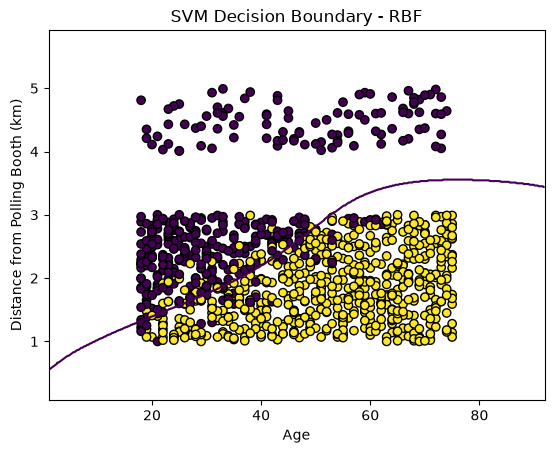

In [119]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC

s = SVC(
    C=0.23481164426718876,
    kernel='rbf',
    gamma='auto'
)

# Train on scaled data
s.fit(X, y)

# Grid in scaled space
x_min = X.iloc[:, 0].min() - 1
x_max = X.iloc[:, 0].max() + 1

y_min = X.iloc[:, 1].min() - 1
y_max = X.iloc[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 500),
    np.linspace(y_min, y_max, 500)
)

# Predict in scaled space
Z = s.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Convert DATA points back to original values
X_original = scaler.inverse_transform(X)

# Convert GRID back to original values
grid_original = scaler.inverse_transform(
    np.c_[xx.ravel(), yy.ravel()]
)

xx_original = grid_original[:, 0].reshape(xx.shape)
yy_original = grid_original[:, 1].reshape(yy.shape)

# Plot
plt.scatter(
    X_original[:, 0],
    X_original[:, 1],
    c=y,
    edgecolors='k'
)

# RBF decision boundary
plt.contour(
    xx_original,
    yy_original,
    Z,
    levels=[0.5]
)

plt.xlabel('Age')
plt.ylabel('Distance from Polling Booth (km)')
plt.title('SVM Decision Boundary - RBF')
plt.show()